In [ ]:
import pandas as pd
import os
import numpy as np

from plotly.subplots import make_subplots
from plotly.offline import init_notebook_mode, iplot, plot
import plotly.graph_objects as go
import plotly.express as px

import matplotlib.pyplot as plt
import plotly.io as pio
from IPython.display import Image

init_notebook_mode(connected=True)

In [ ]:
DATA_DIR = "https://www.kaggle.com/datasets/parsakh/global-e-commerce-and-supply-chain-database?select=transactions.csv"

CUS = os.path.join(DATA_DIR, "/content/customers.csv")
INV = os.path.join(DATA_DIR, '/content/inventory.csv')
MARK_SPN = os.path.join(DATA_DIR, '/content/marketing_spend.csv')
PR_HS = os.path.join(DATA_DIR, '/content/price_history.csv')
PROD = os.path.join(DATA_DIR, '/content/products.csv')
RET = os.path.join(DATA_DIR, '/content/returns.csv')
SUP_COST = os.path.join(DATA_DIR, '/content/supplier_costs.csv')
TRANS = os.path.join(DATA_DIR, '/content/transactions.csv')

In [ ]:
customer_df = pd.read_csv(CUS)
inventory_df = pd.read_csv(INV)
marketing_spend_df = pd.read_csv(MARK_SPN)
price_history_df = pd.read_csv(PR_HS)
products_df = pd.read_csv(PROD)
returns_df = pd.read_csv(RET)
supplier_costs_df = pd.read_csv(SUP_COST)
transactions_df = pd.read_csv(TRANS)

Customers

In [ ]:
print("Columns for customers data: ")
print(f"{' -- \n'.join(customer_df.columns)}")

Columns for customers data: 
customer_id -- 
first_name -- 
last_name -- 
country -- 
currency -- 
age -- 
gender -- 
registration_date -- 
is_premium -- 
email_verified -- 
email


In [ ]:
!pip install --upgrade plotly nbformat

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Load customer_df directly from the local file path
customer_df = pd.read_csv('/content/customers.csv')

# Customer statistics
n_customers = customer_df['customer_id'].nunique()
n_country = customer_df['country'].nunique()
n_currency = customer_df['currency'].nunique()

age_mean = customer_df['age'].mean()
age_std = customer_df['age'].std()

male_pct = customer_df['gender'].eq('M').mean()
female_pct = customer_df['gender'].eq('F').mean()

# Create subplot dashboard
fig = make_subplots(
    rows=2,
    cols=3,
    specs=[
        [{"type": "indicator"}] * 3,
        [{"type": "indicator"}] * 3
    ]
)

metrics = [
    ("Customers", n_customers),
    ("Countries", n_country),
    ("Currencies", n_currency),
    ("Mean Age", round(age_mean, 2)),
    ("Age Std", round(age_std, 2)),
    ("Male %", round(male_pct * 100, 2))
]

for i, (label, value) in enumerate(metrics):
    row = i // 3 + 1
    col = i % 3 + 1
    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label}
        ),
        row=row,
        col=col
    )

fig.update_layout(
    height=500,
    title="Customer KPI Dashboard",
    template="plotly_dark"
)

# Display dashboard
fig.show()

Inventory

In [ ]:
import pandas as pd

# Load inventory_df directly from the local file path
inventory_df = pd.read_csv('/content/inventory.csv')

print("Columns for inventory data: ")
print(f"{' -- \n'.join(inventory_df.columns)}")

Columns for inventory data: 
product_id -- 
category -- 
stock_units -- 
reorder_point -- 
warehouse_location -- 
last_restock_date -- 
supplier_lead_days


In [ ]:
n_cat = inventory_df['category'].nunique()
n_warehouse = inventory_df['warehouse_location'].nunique()
n_products = inventory_df['product_id'].nunique()

total_stock = inventory_df['stock_units'].sum()
avg_stock = inventory_df['stock_units'].mean()
median_stock = inventory_df['stock_units'].median()

low_stock_df = inventory_df[
    inventory_df['stock_units'] < inventory_df['reorder_point']
]

low_stock_count = low_stock_df['product_id'].nunique()
low_stock_ratio = low_stock_count / n_products

overstock_df = inventory_df[
    inventory_df['stock_units'] > inventory_df['reorder_point'] * 2
]

overstock_count = overstock_df['product_id'].nunique()

avg_lead_days = inventory_df['supplier_lead_days'].mean()
max_lead_days = inventory_df['supplier_lead_days'].max()
inventory_df_grouped = inventory_df.groupby('category')

result = inventory_df_grouped.agg({
    'product_id': 'nunique',
    'warehouse_location': 'nunique',
    'supplier_lead_days': 'mean',
    'stock_units': 'sum'
}).rename(columns={
    'product_id': 'distinct_products',
    'warehouse_location': 'distinct_warehouses',
    'supplier_lead_days': 'avg_lead_days',
    'stock_units': 'total_stock'
})

In [ ]:
fig = make_subplots(
    rows=2, cols=4,
    specs=[[{"type": "indicator"}]*4,
           [{"type": "indicator"}]*4],
    horizontal_spacing=0.15,
    vertical_spacing=0.25
)

kpis = [
    ("Categories", n_cat),
    ("Warehouses", n_warehouse),
    ("Products", n_products),
    ("Total Stock", total_stock),
    ("Avg Stock", avg_stock),
    ("Median Stock", median_stock),
    ("Low Stock %", low_stock_ratio * 100),
    ("Overstock", overstock_count)
]
for i, (label, value) in enumerate(kpis):
    r = i // 4 + 1
    c = i % 4 + 1

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label}
        ),
        row=r, col=c
    )

fig.update_layout(
    height=500,
    title="Inventory KPI Dashboard",
    template="plotly_white"
)
# Display dashboard
fig.show()


In [ ]:
#how the number of distinct products carried in each category.

fig = go.Figure()

fig.add_trace(go.Bar(
    x=result.index,
    y=result['distinct_products'],
    name="Products"
))

fig.update_layout(
    title="Distinct Products per Category",
    template="plotly_white",
    xaxis_title="Category",
    yaxis_title="Products"
)

# Display dashboard
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Bar(
    x=result.index,
    y=result['total_stock'],
    name="Stock"
))

fig.update_layout(
    title="Total Stock per Category",
    template="plotly_white",
    xaxis_title="Category",
    yaxis_title="Stock Units"
)

# Display dashboard
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=inventory_df['supplier_lead_days'],
    y=inventory_df['stock_units'],
    mode='markers',
    marker=dict(size=6, opacity=0.6)
))

fig.update_layout(
    title="Supplier Lead Time vs Stock Level",
    xaxis_title="Lead Days",
    yaxis_title="Stock Units",
    template="plotly_white"
)
fig.show()

In [ ]:
risk_by_cat = (
    inventory_df.assign(
        low_stock = inventory_df['stock_units'] < inventory_df['reorder_point']
    )
    .groupby('category')['low_stock']
    .mean()
    * 100
)

fig = go.Figure()

fig.add_trace(go.Bar(
    x=risk_by_cat.index,
    y=risk_by_cat.values
))

fig.update_layout(
    title="Low Stock Risk by Category (%)",
    xaxis_title="Category",
    yaxis_title="Low Stock %",
    template="plotly_white"
)
fig.show()

Marketing Spend

In [ ]:
import pandas as pd
marketing_spend_df = pd.read_csv('/content/marketing_spend.csv')
print("Columns for marketing spent data: ")
print(f"{' -- \n'.join(marketing_spend_df.columns)}")

Columns for marketing spent data: 
year_month -- 
channel -- 
spend_usd -- 
impressions -- 
clicks -- 
ctr -- 
actual_orders -- 
actual_customers -- 
actual_revenue_usd -- 
roas -- 
cac_usd -- 
cost_per_order_usd -- 
month_multiplier


In [ ]:
n_date = marketing_spend_df['year_month'].nunique()
n_channel = marketing_spend_df['channel'].nunique()

t_spent = marketing_spend_df['spend_usd'].sum()
avg_spent = marketing_spend_df['spend_usd'].mean()

avg_ctr = marketing_spend_df['ctr'].mean()

avg_cust_per_spent = marketing_spend_df['actual_customers'].mean()

sum_revenue = marketing_spend_df['actual_revenue_usd'].sum()

total_orders = marketing_spend_df['actual_orders'].sum()

avg_roas = marketing_spend_df['roas'].mean()
weighted_roas = sum_revenue / t_spent

avg_cac = marketing_spend_df['cac_usd'].mean()
avg_cost_per_order = marketing_spend_df['cost_per_order_usd'].mean()

total_impressions = marketing_spend_df['impressions'].sum()
total_clicks = marketing_spend_df['clicks'].sum()

overall_ctr = total_clicks / total_impressions

click_through_rate_mean = marketing_spend_df['ctr'].mean()

customers_per_order = (
    marketing_spend_df['actual_customers'].sum()
    / marketing_spend_df['actual_orders'].sum()
)

revenue_per_customer = (
    marketing_spend_df['actual_revenue_usd'].sum()
    / marketing_spend_df['actual_customers'].sum()
)
n_months = marketing_spend_df['year_month'].nunique()

avg_monthly_spend = t_spent / n_months
avg_monthly_revenue = sum_revenue / n_months

cost_per_click = t_spent / total_clicks

revenue_per_click = sum_revenue / total_clicks

channel_perf = marketing_spend_df.groupby('channel').agg({
    'spend_usd': 'sum',
    'actual_revenue_usd': 'sum',
    'actual_orders': 'sum',
    'impressions': 'sum',
    'clicks': 'sum',
    'roas': 'mean'
})
channel_perf['channel_roas'] = (
    channel_perf['actual_revenue_usd'] / channel_perf['spend_usd']
)

channel_perf['ctr'] = (
    channel_perf['clicks'] / channel_perf['impressions']
)

In [ ]:
fig = make_subplots(
    rows=2, cols=4,
    specs=[[{"type": "indicator"}]*4,
           [{"type": "indicator"}]*4],
    horizontal_spacing=0.15,
    vertical_spacing=0.25
)

kpis = [
    ("Spend ($)", t_spent),
    ("Revenue ($)", sum_revenue),
    ("Orders", total_orders),
    ("Channels", n_channel),
    ("Months", n_date),
    ("Avg ROAS", avg_roas),
    ("Weighted ROAS", weighted_roas),
    ("Avg CAC", avg_cac)
]
for i, (label, value) in enumerate(kpis):
    r = i // 4 + 1
    c = i % 4 + 1

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label}
        ),
        row=r, col=c
    )

fig.update_layout(
    title="Marketing KPI Dashboard",
    height=520,
    template="plotly_white"
)
fig.show()

In [ ]:
monthly = marketing_spend_df.groupby("year_month").agg({
    "spend_usd": "sum",
    "actual_revenue_usd": "sum"
}).reset_index()

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=monthly["year_month"],
    y=monthly["spend_usd"],
    name="Spend",
    mode="lines+markers"
))

fig.add_trace(go.Scatter(
    x=monthly["year_month"],
    y=monthly["actual_revenue_usd"],
    name="Revenue",
    mode="lines+markers"
))
fig.update_layout(
    title="Marketing Spend vs Revenue Over Time",
    xaxis_title="Month",
    yaxis_title="USD",
    template="plotly_white"
)
fig.show()

In [ ]:
channel_perf = marketing_spend_df.groupby("channel").agg({
    "spend_usd": "sum",
    "actual_revenue_usd": "sum",
    "actual_orders": "sum",
    "impressions": "sum",
    "clicks": "sum"
}).reset_index()

channel_perf["roas"] = channel_perf["actual_revenue_usd"] / channel_perf["spend_usd"]
channel_perf["ctr"] = channel_perf["clicks"] / channel_perf["impressions"]

fig = go.Figure()

fig.add_trace(go.Bar(
    x=channel_perf["channel"],
    y=channel_perf["roas"]
))
fig.update_layout(
    title="ROAS by Channel",
    template="plotly_white",
    xaxis_title="Channel",
    yaxis_title="ROAS"
)
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Bar(
    x=channel_perf["channel"],
    y=channel_perf["spend_usd"],
    name="Spend"
))

fig.add_trace(go.Bar(
    x=channel_perf["channel"],
    y=channel_perf["actual_revenue_usd"],
    name="Revenue"
))

fig.update_layout(
    barmode="group",
    title="Spend vs Revenue by Channel",
    template="plotly_white"
)
fig.show()

Pricing History

In [ ]:
import pandas as pd
price_history_df = pd.read_csv('/content/price_history.csv')
print("Columns for price history data: ")
print(f"{' -- \n'.join(price_history_df.columns)}")

Columns for price history data: 
product_id -- 
category -- 
year_month -- 
listed_price_usd -- 
base_price_usd -- 
competitor_price_usd -- 
price_index -- 
is_promotional -- 
price_elasticity -- 
units_sold -- 
revenue_usd -- 
margin_pct


In [ ]:
n_products = price_history_df['product_id'].nunique()
n_category = price_history_df['category'].nunique()

total_units = price_history_df['units_sold'].sum()
total_revenue = price_history_df['revenue_usd'].sum()

avg_margin = price_history_df['margin_pct'].mean().round(2)
avg_price_index = price_history_df['price_index'].mean()

promo_rate = price_history_df['is_promotional'].mean() * 100

avg_elasticity = price_history_df['price_elasticity'].mean().round(2)

In [ ]:
fig = make_subplots(
    rows=2, cols=4,
    specs=[[{"type": "indicator"}]*4,
           [{"type": "indicator"}]*4],
    horizontal_spacing=0.15,
    vertical_spacing=0.25
)

kpis = [
    ("Products", n_products),
    ("Categories", n_category),
    ("Units Sold", total_units),
    ("Revenue ($)", total_revenue),
    ("Avg Margin %", avg_margin),
    ("Avg Price Index", avg_price_index),
    ("Promo Rate %", promo_rate),
    ("Avg Elasticity", avg_elasticity)
]
for i, (label, value) in enumerate(kpis):
    r = i // 4 + 1
    c = i % 4 + 1

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label}
        ),
        row=r, col=c
    )

fig.update_layout(
    title="Pricing & Demand KPI Dashboard",
    height=520,
    template="plotly_white"
)
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    y=price_history_df['listed_price_usd'],
    name="Listed Price",
    mode="lines"
))

fig.add_trace(go.Scatter(
    y=price_history_df['base_price_usd'],
    name="Base Price",
    mode="lines"
))

fig.add_trace(go.Scatter(
    y=price_history_df['competitor_price_usd'],
    name="Competitor Price",
    mode="lines"
))
fig.update_layout(
    title="Price Positioning Over Records",
    template="plotly_white"
)
fig.show()

In [ ]:
cat_perf = price_history_df.groupby("category").agg({
    "units_sold": "sum",
    "revenue_usd": "sum",
    "margin_pct": "mean"
}).reset_index()

fig = go.Figure()

fig.add_trace(go.Bar(
    x=cat_perf["category"],
    y=cat_perf["revenue_usd"]
))

fig.update_layout(
    title="Revenue by Category",
    template="plotly_white",
    xaxis_title="Category",
    yaxis_title="Revenue ($)"
)
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Bar(
    x=cat_perf["category"],
    y=cat_perf["units_sold"]
))

fig.update_layout(
    title="Units Sold by Category",
    template="plotly_white"
)
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=price_history_df["price_index"],
    y=price_history_df["units_sold"],
    mode="markers",
    marker=dict(size=6, opacity=0.5)
))

fig.update_layout(
    title="Price Index vs Units Sold",
    xaxis_title="Price Index",
    yaxis_title="Units Sold",
    template="plotly_white"
)
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Histogram(
    x=price_history_df["price_elasticity"],
    nbinsx=30
))

fig.update_layout(
    title="Price Elasticity Distribution",
    template="plotly_white"
)
fig.show()

In [ ]:
#Compare margin percentage for promotional versus non-promotional records to see how promotions affect profitability.
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=price_history_df["is_promotional"],
    y=price_history_df["margin_pct"],
    mode="markers"
))

fig.update_layout(
    title="Promotion vs Margin",
    xaxis_title="Is Promotional",
    yaxis_title="Margin %",
    template="plotly_white"
)
fig.show()

Compute the gap between the listed price and the competitor price for each record, and plot its distribution to see how often the company prices above or below competitors.

In [ ]:
price_history_df["price_gap"] = (
    price_history_df["listed_price_usd"] - price_history_df["competitor_price_usd"]
)

fig = go.Figure()

fig.add_trace(go.Histogram(
    x=price_history_df["price_gap"],
    nbinsx=40
))

fig.update_layout(
    title="Price Gap vs Competitor",
    template="plotly_white"
)
fig.show()

Products

In [ ]:
products_df = pd.read_csv('/content/products.csv')
print("Columns for products data: ")
print(f"{' -- \n'.join(products_df.columns)}")

Columns for products data: 
product_id -- 
name -- 
category -- 
brand -- 
unit_price_usd -- 
unit_cost_usd -- 
weight_kg -- 
is_active -- 
launch_date


In [ ]:
n_products = products_df['product_id'].nunique()
n_categories = products_df['category'].nunique()
n_brands = products_df['brand'].nunique()

avg_price = products_df['unit_price_usd'].mean()
avg_cost = products_df['unit_cost_usd'].mean()

avg_margin = ((products_df['unit_price_usd'] - products_df['unit_cost_usd'])
              / products_df['unit_price_usd']).mean() * 100

active_rate = products_df['is_active'].mean() * 100

In [ ]:
fig = make_subplots(
    rows=2, cols=4,
    specs=[[{"type": "indicator"}]*4,
           [{"type": "indicator"}]*4],
    horizontal_spacing=0.15,
    vertical_spacing=0.25
)

kpis = [
    ("Products", n_products),
    ("Categories", n_categories),
    ("Brands", n_brands),
    ("Avg Price ($)", avg_price),
    ("Avg Cost ($)", avg_cost),
    ("Avg Margin %", avg_margin),
    ("Active %", active_rate),
]
for i, (label, value) in enumerate(kpis):
    r = i // 4 + 1
    c = i % 4 + 1

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label}
        ),
        row=r, col=c
    )

fig.update_layout(
    title="Product Portfolio KPI Dashboard",
    height=500,
    template="plotly_white"
)
fig.show()

In [ ]:
products_df["margin_pct"] = (
    (products_df["unit_price_usd"] - products_df["unit_cost_usd"])
    / products_df["unit_price_usd"]
) * 100

fig = go.Figure()

fig.add_trace(go.Histogram(
    x=products_df["margin_pct"],
    nbinsx=40
))

fig.update_layout(
    title="Margin Distribution (%)",
    template="plotly_white",
    xaxis_title="Margin %"
)
fig.show()

In [ ]:
cat_perf = products_df.groupby("category").agg({
    "unit_price_usd": "mean",
    "unit_cost_usd": "mean",
    "margin_pct": "mean",
    "product_id": "count"
}).rename(columns={"product_id": "product_count"}).reset_index()

fig = go.Figure()

fig.add_trace(go.Bar(
    x=cat_perf["category"],
    y=cat_perf["margin_pct"]
))

fig.update_layout(
    title="Average Margin % by Category",
    template="plotly_white",
    xaxis_title="Category",
    yaxis_title="Margin %"
)
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=products_df["unit_cost_usd"],
    y=products_df["unit_price_usd"],
    mode="markers",
    marker=dict(size=6, opacity=0.6)
))

fig.add_shape(
    type="line",
    x0=products_df["unit_cost_usd"].min(),
    y0=products_df["unit_cost_usd"].min(),
    x1=products_df["unit_cost_usd"].max(),
    y1=products_df["unit_cost_usd"].max(),
    line=dict(dash="dash")
)

fig.update_layout(
    title="Cost vs Price Positioning",
    xaxis_title="Cost ($)",
    yaxis_title="Price ($)",
    template="plotly_white"
)
fig.show()

In [ ]:
brand_perf = products_df.groupby("brand").agg({
    "unit_price_usd": "mean",
    "unit_cost_usd": "mean",
    "margin_pct": "mean",
    "product_id": "count"
}).reset_index()

fig = go.Figure()

fig.add_trace(go.Bar(
    x=brand_perf["brand"],
    y=brand_perf["margin_pct"]
))

fig.update_layout(
    title="Brand-Level Average Margin",
    template="plotly_white",
    xaxis_title="Brand",
    yaxis_title="Margin %"
)
fig.show()

In [ ]:
products_df["launch_date"] = pd.to_datetime(products_df["launch_date"])

launch_trend = products_df.groupby(
    products_df["launch_date"].dt.to_period("M")
)["product_id"].count().reset_index()

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=launch_trend["launch_date"].astype(str),
    y=launch_trend["product_id"],
    mode="lines+markers"
))

fig.update_layout(
    title="Product Launch Trend",
    template="plotly_white",
    xaxis_title="Month",
    yaxis_title="New Products"
)

fig.show()

Returns

In [ ]:
returns_df = pd.read_csv('/content/returns.csv')
print("Columns for returns data: ")
print(f"{' -- \n'.join(returns_df.columns)}")

Columns for returns data: 
return_id -- 
transaction_id -- 
customer_id -- 
product_id -- 
return_date -- 
reason -- 
refund_amount_usd -- 
restocked


In [ ]:
n_returns = returns_df['return_id'].nunique()
n_products_returned = returns_df['product_id'].nunique()
n_customers_returned = returns_df['customer_id'].nunique()

total_refund = returns_df['refund_amount_usd'].sum()
avg_refund = returns_df['refund_amount_usd'].mean()

restock_rate = returns_df['restocked'].mean() * 100

In [ ]:
fig = make_subplots(
    rows=2, cols=4,
    specs=[[{"type": "indicator"}]*4,
           [{"type": "indicator"}]*4],
    horizontal_spacing=0.15,
    vertical_spacing=0.25
)

kpis = [
    ("Returns", n_returns),
    ("Products Returned", n_products_returned),
    ("Customers Returned", n_customers_returned),
    ("Total Refund ($)", total_refund),
    ("Avg Refund ($)", avg_refund),
    ("Restock Rate %", restock_rate),
]
for i, (label, value) in enumerate(kpis):
    r = i // 4 + 1
    c = i % 4 + 1

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label}
        ),
        row=r, col=c
    )

fig.update_layout(
    title="Returns KPI Dashboard",
    height=500,
    template="plotly_white"
)
fig.show()

In [ ]:
return_rate = returns_df['return_id'].nunique() / returns_df['transaction_id'].nunique()

reason_counts = returns_df['reason'].value_counts()

fig = go.Figure()

fig.add_trace(go.Bar(
    x=reason_counts.index,
    y=reason_counts.values
))

fig.update_layout(
    title="Return Reasons Distribution",
    template="plotly_white",
    xaxis_title="Reason",
    yaxis_title="Count"
)
fig.show()

In [ ]:
product_returns = returns_df.groupby("product_id").agg({
    "return_id": "count",
    "refund_amount_usd": "sum"
}).rename(columns={"return_id": "return_count"}).reset_index()

top_returns = product_returns.sort_values("return_count", ascending=False).head(10)

fig = go.Figure()

fig.add_trace(go.Bar(
    x=top_returns["product_id"].astype(str),
    y=top_returns["return_count"]
))

fig.update_layout(
    title="Top 10 Returned Products",
    template="plotly_white",
    xaxis_title="Product ID",
    yaxis_title="Return Count"
)
fig.show()

In [ ]:
customer_returns = returns_df.groupby("customer_id").agg({
    "return_id": "count",
    "refund_amount_usd": "sum"
}).rename(columns={"return_id": "return_count"}).reset_index()

top_customers = customer_returns.sort_values("return_count", ascending=False).head(10)

fig = go.Figure()

fig.add_trace(go.Bar(
    x=top_customers["customer_id"].astype(str),
    y=top_customers["return_count"]
))

fig.update_layout(
    title="Top Returning Customers",
    template="plotly_white",
    xaxis_title="Customer ID",
    yaxis_title="Return Count"
)
fig.show()

In [ ]:
restock_summary = returns_df.groupby("restocked")["refund_amount_usd"].agg(["count", "sum"])

fig = go.Figure()

fig.add_trace(go.Bar(
    x=["Not Restocked", "Restocked"],
    y=restock_summary["sum"]
))

fig.update_layout(
    title="Refund Amount by Restock Status",
    template="plotly_white",
    yaxis_title="Refund ($)"
)
fig.show()

Supplier Costs

In [ ]:
supplier_costs_df = pd.read_csv('/content/supplier_costs.csv')
print("Columns for supplier costs data: ")
print(f"{' -- \n'.join(supplier_costs_df.columns)}")

Columns for supplier costs data: 
product_id -- 
category -- 
supplier_name -- 
supplier_rank -- 
unit_cost_usd -- 
ordering_cost_usd -- 
annual_holding_cost_usd -- 
holding_cost_pct -- 
lead_time_days -- 
min_order_qty -- 
reliability_score -- 
is_primary


In [ ]:
n_suppliers = supplier_costs_df['supplier_name'].nunique()
n_products = supplier_costs_df['product_id'].nunique()
n_categories = supplier_costs_df['category'].nunique()

avg_unit_cost = supplier_costs_df['unit_cost_usd'].mean()
avg_ordering_cost = supplier_costs_df['ordering_cost_usd'].mean()
avg_holding_cost = supplier_costs_df['annual_holding_cost_usd'].mean()

avg_reliability = supplier_costs_df['reliability_score'].mean()
primary_supplier_rate = supplier_costs_df['is_primary'].mean() * 100

avg_lead_time = supplier_costs_df['lead_time_days'].mean()
avg_min_order_qty = supplier_costs_df['min_order_qty'].mean()

In [ ]:
fig = make_subplots(
    rows=2, cols=4,
    specs=[[{"type": "indicator"}]*4,
           [{"type": "indicator"}]*4],
    horizontal_spacing=0.15,
    vertical_spacing=0.25
)

kpis = [
    ("Suppliers", n_suppliers),
    ("Products", n_products),
    ("Categories", n_categories),
    ("Avg Unit Cost", avg_unit_cost),
    ("Avg Ordering Cost", avg_ordering_cost),
    ("Avg Holding Cost", avg_holding_cost),
    ("Reliability Score", avg_reliability),
    ("Lead Time (days)", avg_lead_time)
]
for i, (label, value) in enumerate(kpis):
    r = i // 4 + 1
    c = i % 4 + 1

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label}
        ),
        row=r, col=c
    )

fig.update_layout(
    title="Supplier & Procurement KPI Dashboard",
    height=520,
    template="plotly_white"
)
fig.show()

In [ ]:
cost_components = {
    "Unit Cost": supplier_costs_df["unit_cost_usd"].sum(),
    "Ordering Cost": supplier_costs_df["ordering_cost_usd"].sum(),
    "Holding Cost": supplier_costs_df["annual_holding_cost_usd"].sum()
}

fig = go.Figure()

fig.add_trace(go.Pie(
    labels=list(cost_components.keys()),
    values=list(cost_components.values())
))

fig.update_layout(
    title="Cost Structure Breakdown"
)
fig.show()

In [ ]:
cat_cost = supplier_costs_df.groupby("category").agg({
    "unit_cost_usd": "mean",
    "lead_time_days": "mean",
    "reliability_score": "mean"
}).reset_index()

fig = go.Figure()

fig.add_trace(go.Bar(
    x=cat_cost["category"],
    y=cat_cost["unit_cost_usd"]
))

fig.update_layout(
    title="Average Unit Cost by Category",
    xaxis_title="Category",
    yaxis_title="Unit Cost ($)",
    template="plotly_white"
)
fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=supplier_costs_df["min_order_qty"],
    y=supplier_costs_df["unit_cost_usd"],
    mode="markers",
    marker=dict(size=7, opacity=0.5)
))

fig.update_layout(
    title="MOQ vs Unit Cost",
    xaxis_title="Minimum Order Quantity",
    yaxis_title="Unit Cost ($)",
    template="plotly_white"
)
fig.show()

Transactions

In [ ]:
transactions_df = pd.read_csv('/content/transactions.csv')
print("Columns for transactions data: ")
print(f"{' -- \n'.join(transactions_df.columns)}")

Columns for transactions data: 
transaction_id -- 
customer_id -- 
product_id -- 
date -- 
quantity -- 
unit_price_usd -- 
discount_pct -- 
revenue_usd -- 
cost_usd -- 
profit_usd -- 
shipping_cost_usd -- 
channel -- 
payment_method -- 
status -- 
country -- 
category


In [ ]:
transactions_df["date"] = pd.to_datetime(transactions_df["date"], errors="coerce")

transactions_df = transactions_df.sort_values("date")

transactions_df["year"] = transactions_df["date"].dt.year
transactions_df["month"] = transactions_df["date"].dt.to_period("M").astype(str)
transactions_df["day"] = transactions_df["date"].dt.date

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=["Revenue", "Profit"])

fig.add_trace(
    go.Histogram(x=transactions_df["revenue_usd"], nbinsx=50),
    row=1, col=1
)

fig.add_trace(
    go.Histogram(x=transactions_df["profit_usd"], nbinsx=50),
    row=1, col=2
)

fig.update_layout(title="Revenue & Profit Distributions", showlegend=False)
fig.show()

In [ ]:
import plotly.express as px

fig = px.scatter(
    transactions_df,
    x="revenue_usd",
    y="profit_usd",
    color="category",
    opacity=0.5,
    title="Profit vs Revenue"
)
fig.show()

In [ ]:
daily = transactions_df.groupby("date")[["revenue_usd", "profit_usd"]].sum().reset_index()

fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(
    go.Scatter(x=daily["date"], y=daily["revenue_usd"], name="Revenue"),
    secondary_y=False
)

fig.add_trace(
    go.Scatter(x=daily["date"], y=daily["profit_usd"], name="Profit"),
    secondary_y=True
)

fig.update_layout(title="Revenue & Profit Over Time")
fig.show()

In [ ]:
top_customers = transactions_df.groupby("customer_id")["revenue_usd"].sum().nlargest(15).reset_index()

fig = px.bar(
    top_customers,
    x="customer_id",
    y="revenue_usd",
    title="Top Customers by Revenue"
)
fig.show()

In [ ]:
cust_freq = transactions_df["customer_id"].value_counts().head(20).reset_index()
cust_freq.columns = ["customer_id", "transactions"]

fig = px.bar(
    cust_freq,
    x="customer_id",
    y="transactions",
    title="Most Active Customers"
)
fig.show()

In [ ]:
top_products = transactions_df.groupby("product_id")["revenue_usd"].sum().nlargest(15).reset_index()

fig = px.bar(
    top_products,
    x="product_id",
    y="revenue_usd",
    title="Top Products by Revenue"
)
fig.show()

In [ ]:
cat = transactions_df.groupby("category")["revenue_usd"].sum().reset_index()

fig = px.pie(
    cat,
    names="category",
    values="revenue_usd",
    title="Revenue Share by Category"
)
fig.show()

In [ ]:
cat_profit = transactions_df.groupby("category")[["revenue_usd", "profit_usd"]].sum().reset_index()

fig = px.bar(
    cat_profit,
    x="category",
    y=["revenue_usd", "profit_usd"],
    barmode="group",
    title="Revenue vs Profit by Category"
)
fig.show()

In [ ]:
channel_perf = transactions_df.groupby("channel")[["revenue_usd", "profit_usd"]].sum().reset_index()

fig = px.bar(
    channel_perf,
    x="channel",
    y="revenue_usd",
    color="profit_usd",
    title="Channel Performance (Revenue vs Profit)"
)
fig.show()

In [ ]:
payment = transactions_df.groupby("payment_method")["revenue_usd"].sum().reset_index()

fig = px.bar(
    payment,
    x="payment_method",
    y="revenue_usd",
    title="Revenue by Payment Method"
)
fig.show()

In [ ]:
fig = px.scatter(
    transactions_df,
    x="discount_pct",
    y="revenue_usd",
    opacity=0.5,
    title="Discount vs Revenue"
)
fig.show()

In [ ]:
country = transactions_df.groupby("country")["revenue_usd"].sum().nlargest(15).reset_index()

fig = px.bar(
    country,
    x="country",
    y="revenue_usd",
    title="Top Countries by Revenue"
)
fig.show()

In [ ]:
status = transactions_df["status"].value_counts().reset_index()
status.columns = ["status", "count"]

fig = px.bar(
    status,
    x="status",
    y="count",
    title="Transaction Status Distribution"
)
fig.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

balanced_accuracy = balanced_accuracy_score(
    y_test, y_pred
)

# ROC-AUC
y_prob = model.predict_proba(X_test)[:, 1]

if y_test.nunique() == 2:
    auc = roc_auc_score(y_test, y_prob)
else:
    auc = None

# Print results
print("========== CUSTOMER MODEL PERFORMANCE ==========")

print("Accuracy          :", round(accuracy * 100, 2), "%")
print("Precision         :", round(precision, 4))
print("Recall            :", round(recall, 4))
print("F1-Score          :", round(f1, 4))
print("Balanced Accuracy :", round(balanced_accuracy, 4))

if auc is not None:
    print("ROC-AUC Score     :", round(auc, 4))

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Premium', 'Premium'],
    zero_division=0
))

========== CUSTOMER MODEL PERFORMANCE ==========
Accuracy          : 94.0 %
Precision         : 1.0
Recall            : 0.25
F1-Score          : 0.4
Balanced Accuracy : 0.625
ROC-AUC Score     : 0.9647

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

 Non-Premium       0.94      1.00      0.97        92
     Premium       1.00      0.25      0.40         8

    accuracy                           0.94       100
   macro avg       0.97      0.62      0.68       100
weighted avg       0.94      0.94      0.92       100




========== CONFUSION MATRIX ==========
[[92  0]
 [ 6  2]]


Text(58.22222222222221, 0.5, 'Actual Values')

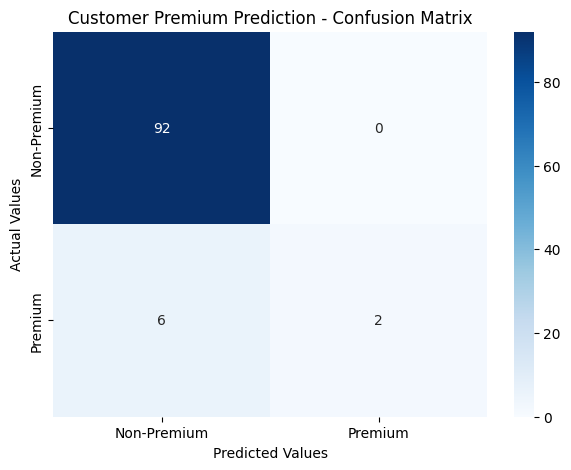

In [ ]:
print("\n========== CONFUSION MATRIX ==========")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Premium', 'Premium'],
    yticklabels=['Non-Premium', 'Premium']
)

plt.title("Customer Premium Prediction - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

Customer Target Distribution:
is_premium
False    6251
True     1749
Name: count, dtype: int64

Percentage Distribution:
is_premium
False    78.1375
True     21.8625
Name: proportion, dtype: float64


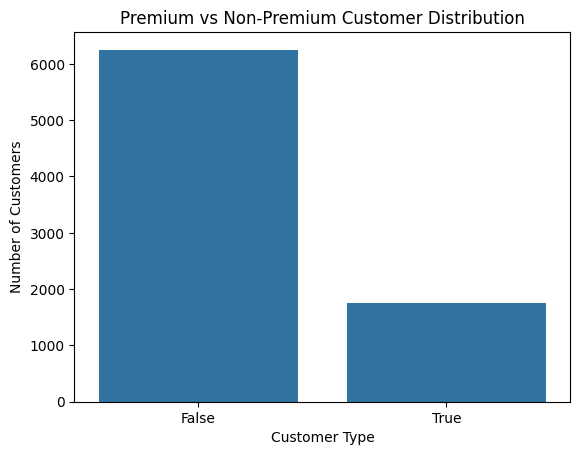

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

customer_df = pd.read_csv('/content/customers.csv')

print("Customer Target Distribution:")
print(customer_df['is_premium'].value_counts())

print("\nPercentage Distribution:")
print(customer_df['is_premium'].value_counts(normalize=True) * 100)

sns.countplot(data=customer_df, x='is_premium')
plt.title('Premium vs Non-Premium Customer Distribution')
plt.xlabel('Customer Type')
plt.ylabel('Number of Customers')
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

df = customer_df.copy()

# Convert target into 0 and 1
y = df['is_premium'].astype(int)

# Prepare customer features
X = df[['age', 'gender', 'country', 'currency',
        'email_verified']]

# Feature groups
numerical_features = ['age']
categorical_features = [
    'gender', 'country', 'currency', 'email_verified'
]

# Preprocessing
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'),
     numerical_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

# Split while maintaining class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Model
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
is_premium
0    78.140625
1    21.859375
Name: proportion, dtype: float64

Testing distribution:
is_premium
0    78.125
1    21.875
Name: proportion, dtype: float64


Confusion Matrix:
[[836 414]
 [230 120]]

Classification Report:
              precision    recall  f1-score   support

 Non-Premium       0.78      0.67      0.72      1250
     Premium       0.22      0.34      0.27       350

    accuracy                           0.60      1600
   macro avg       0.50      0.51      0.50      1600
weighted avg       0.66      0.60      0.62      1600

Accuracy: 0.5975
Precision: 0.2247191011235955
Recall: 0.34285714285714286
F1 Score: 0.27149321266968324


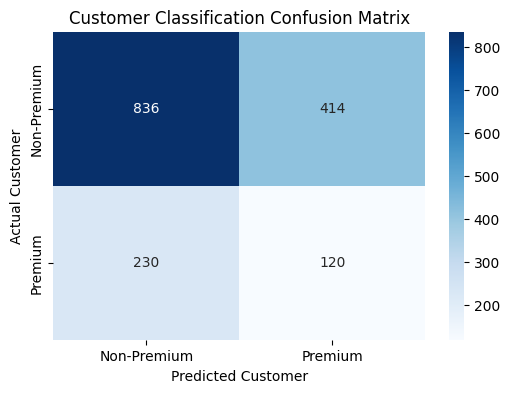

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Premium', 'Premium'],
    zero_division=0
))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Premium', 'Premium'],
    yticklabels=['Non-Premium', 'Premium']
)

plt.xlabel('Predicted Customer')
plt.ylabel('Actual Customer')
plt.title('Customer Classification Confusion Matrix')
plt.show()

Disruption Risk Distribution:
disruption_risk
0    460
1     40
Name: count, dtype: int64

Percentage Distribution:
disruption_risk
0    92.0
1     8.0
Name: proportion, dtype: float64


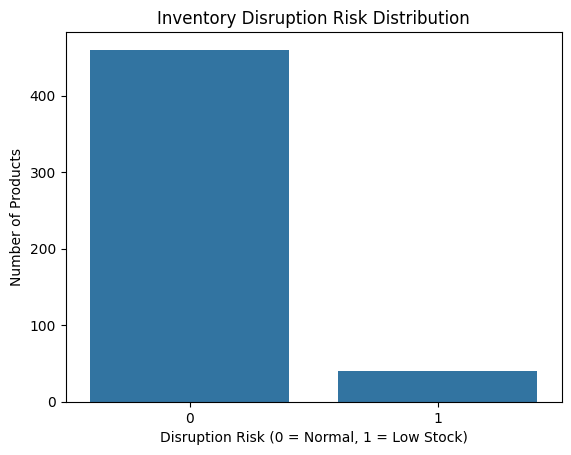

Training Data: (400, 4)
Testing Data: (100, 4)

Training Distribution:
disruption_risk
0    92.0
1     8.0
Name: proportion, dtype: float64

Testing Distribution:
disruption_risk
0    92.0
1     8.0
Name: proportion, dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Load inventory dataset
inventory_df = pd.read_csv('/content/inventory.csv')

# Create disruption risk target
inventory_df['disruption_risk'] = (
    inventory_df['stock_units'] < inventory_df['reorder_point']
).astype(int)

# Check target distribution
print("Disruption Risk Distribution:")
print(inventory_df['disruption_risk'].value_counts())

print("\nPercentage Distribution:")
print(inventory_df['disruption_risk'].value_counts(normalize=True) * 100)

# Visualize distribution
sns.countplot(data=inventory_df, x='disruption_risk')
plt.title('Inventory Disruption Risk Distribution')
plt.xlabel('Disruption Risk (0 = Normal, 1 = Low Stock)')
plt.ylabel('Number of Products')
plt.show()

# Select input features
X = inventory_df[
    ['category', 'reorder_point',
     'warehouse_location', 'supplier_lead_days']
]

# Target variable
y = inventory_df['disruption_risk']

# Check that both classes exist
if y.nunique() != 2:
    raise ValueError("The target must contain both normal and disruption-risk classes.")

# Training and testing split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True) * 100)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Feature types
numeric_features = ['reorder_point', 'supplier_lead_days']

categorical_features = [
    'category',
    'warehouse_location'
]

# Preprocessing
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'),
     numeric_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

# Random Forest model
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Model evaluation
print("MODEL EVALUATION")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal Stock', 'Disruption Risk'],
    zero_division=0
))

MODEL EVALUATION
Accuracy: 0.92
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
                 precision    recall  f1-score   support

   Normal Stock       0.92      1.00      0.96        92
Disruption Risk       0.00      0.00      0.00         8

       accuracy                           0.92       100
      macro avg       0.46      0.50      0.48       100
   weighted avg       0.85      0.92      0.88       100



Confusion Matrix:
[[92  0]
 [ 8  0]]


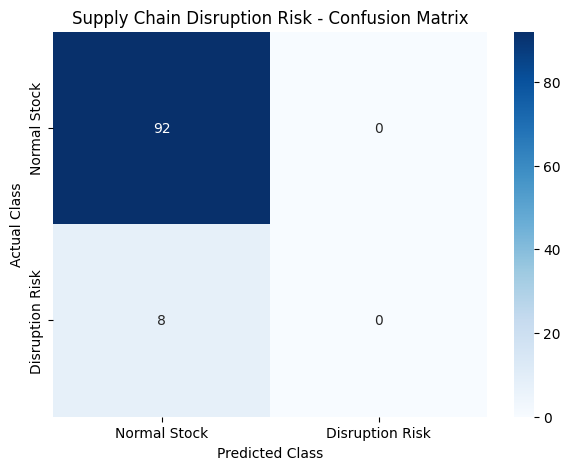

In [ ]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Visualize
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal Stock', 'Disruption Risk'],
    yticklabels=['Normal Stock', 'Disruption Risk']
)

plt.title('Supply Chain Disruption Risk - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()